# 12 · Qwen3-Reranker-4B as the second stage (Phase 5, task 5.8)

Notebook 11 found that pointwise Llama 3.2 3B does not improve Qwen3-Embedding's full-corpus ranking. This notebook asks whether a model **trained for reranking** does. The protocol is the same: lists, candidates, α tuned on dev, metrics and tests.

- **Model.** `Qwen/Qwen3-Reranker-4B`, revision `22e6836`, run with the model card's reference implementation in float16 on MPS.
  - The score is P(yes) from the "yes"/"no" logits.
  - `scripts/check_qwen3_reranker.py` found float16 within 0.006 of float32 (Spearman 1.0) and no NaNs. The sentence-transformers path agreed with the reference at Spearman 0.998.
- **Instruction**, fixed before any result was seen: "Given the title and abstract of a scientific paper, retrieve papers that it cites".
- **Inputs.** The same text as every other method: query 1,500 characters, candidates 600.
- **Comparison.** Notebook 11's Llama scores are read from their cache, so both second stages appear in one table.
- **Validity note.** The model was released in 2025 and may have seen the 2020–2024 query papers and their reference lists in training. Any gain could partly reflect memorization, which this benchmark cannot separate out (as for every pretrained model here).

Scores are cached per (query, document) in `v2/runs_corpus/pointwise_qwen3_reranker.jsonl`.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import numpy as np
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src.figures import save, setup_style
setup_style()

In [2]:
T, B, NORM = 5, 0.1, "count"   # chosen on dev in notebook 10
K = 100
ALPHAS = [round(a, 1) for a in np.linspace(0, 1, 11)]
BATCH = 8                      # 4, 8 and 16 gave 0.46, 0.46 and 0.45 s per pair on a 32-pair probe

In [3]:
import json

from src.cograph import Rules
from src.expansion import cocitation_scores, grit_expand
from src.pipeline_v2 import EMB_CACHE
from src.retrieval import dense_matrix, load_phase5

S = load_phase5(RESEARCH)
g, labels, qids, idx, masks, pos_idx = S["g"], S["labels"], S["qids"], S["idx"], S["masks"], S["pos_idx"]
doc_ids = S["doc_ids"]
qrow = {q: i for i, q in enumerate(qids)}
dev_q = [q for q in qids if labels[q]["split"] == "dev"]
test_q = [q for q in qids if labels[q]["split"] == "test"]
qwen = dense_matrix("qwen", S["doc_texts"], S["query_texts"], EMB_CACHE / S["tag"])
with (RESEARCH / "v2" / "runs_corpus" / "stage1" / "qwen.jsonl").open() as f:
    top_qwen = {r["pi_id"]: np.array([idx[d] for d in r["top100"]]) for r in map(json.loads, f)}

lists = {"Qwen3-Embedding": top_qwen, "Co-citation expanded": {}}
graph_added = {}
for q in qids:
    top = top_qwen[q]
    gs = cocitation_scores(g, top[:T], g.allowed(q, labels[q]["date"], Rules()), NORM)
    new, added = grit_expand(top, T, B, gs, masks[q].copy(), qwen[qrow[q]])
    lists["Co-citation expanded"][q], graph_added[q] = new, set(added.tolist())
rec = {name: np.mean([np.isin(pos_idx[q], L[q]).mean() for q in test_q]) * 100 for name, L in lists.items()}
print({k: round(v, 1) for k, v in rec.items()})
assert abs(rec["Co-citation expanded"] - 64.9) < 0.05, "expanded lists must match notebook 10"

{'Qwen3-Embedding': np.float64(64.0), 'Co-citation expanded': np.float64(64.9)}


### Scoring with Qwen3-Reranker-4B

In [4]:
import time

from tqdm.auto import tqdm

from src.rerank import PointwiseCache, Qwen3Reranker

to_score = {q: sorted({doc_ids[i] for L in lists.values() for i in L[q]}) for q in qids}
print(f"pairs to score: {sum(map(len, to_score.values()))}")
reranker = Qwen3Reranker(batch_size=BATCH)
caches = {"Qwen3-Reranker-4B": PointwiseCache(RESEARCH / "v2" / "runs_corpus" / "pointwise_qwen3_reranker.jsonl", scorer=reranker),
          "Llama 3.2 3B": PointwiseCache(RESEARCH / "v2" / "runs_corpus" / "pointwise_llama.jsonl")}
text_of = dict(zip(doc_ids, S["doc_texts"]))
t0, new = time.time(), 0
for q in tqdm(dev_q + test_q, desc="Qwen3-Reranker-4B"):  # dev first, so tuning data exists early
    new += caches["Qwen3-Reranker-4B"].ensure(q, S["query_texts"][qrow[q]], to_score[q], text_of.get)
elapsed = time.time() - t0
print(f"new pairs: {new} in {elapsed / 60:.1f} min ({elapsed / max(new, 1):.3f} s/pair)")
missing = [(q, d) for q in qids for d in to_score[q] if (q, d) not in caches["Llama 3.2 3B"].scores]
assert not missing, "Llama scores from notebook 11 must cover the same pairs"

pairs to score: 17939


new pairs: 17939 in 256.9 min (0.859 s/pair)


In [5]:
status = pd.Series([caches["Qwen3-Reranker-4B"].scores[(q, d)]["status"] for q in qids for d in to_score[q]]).value_counts()
print("Qwen3-Reranker status:", status.to_dict())

Qwen3-Reranker status: {'ok': 17939}


### Separation of cited papers from the other listed candidates

In [6]:
from sklearn.metrics import roc_auc_score

rows = []
for q in qids:
    docs = to_score[q]
    y = np.isin([idx[d] for d in docs], pos_idx[q])
    if 0 < y.sum() < len(y):
        row = {"split": labels[q]["split"], "Qwen3-Embedding": roc_auc_score(y, qwen[qrow[q]][[idx[d] for d in docs]])}
        for name, c in caches.items():
            row[name] = roc_auc_score(y, c.get(q, docs))
        rows.append(row)
pd.DataFrame(rows).groupby("split").mean().round(3)

,Qwen3-Embedding,Qwen3-Reranker-4B,Llama 3.2 3B
split,,,
dev,0.770,0.833,0.635
test,0.761,0.824,0.663


### α on dev

In [7]:
from src.rerank import fuse_order
from src.retrieval import query_metrics

def evaluate(list_name, scorer, alpha, queries):
    out = {}
    for q in queries:
        order = lists[list_name][q]
        docs = [doc_ids[i] for i in order]
        new = fuse_order(order, caches[scorer].get(q, docs), qwen[qrow[q]][order], alpha)
        m, _ = query_metrics(new, pos_idx[q])
        out[q] = {**m, "order": new}
    return out

dev_rows = [{"scorer": s, "list": name, "alpha": a,
             **pd.DataFrame(evaluate(name, s, a, dev_q)).T[["ndcg@10", "mrr", "rprec"]].astype(float).mean()}
            for s in caches for name in lists for a in ALPHAS]
dev_tab = pd.DataFrame(dev_rows)
ALPHA = {}
for s in caches:
    d = dev_tab[(dev_tab.scorer == s) & (dev_tab["list"] == "Qwen3-Embedding")].sort_values(["ndcg@10", "alpha"], ascending=[False, True])
    ALPHA[s] = float(d.iloc[0]["alpha"])
print("alpha chosen on dev (Qwen3-Embedding list, nDCG@10):", ALPHA)
dev_tab.pivot_table(index="alpha", columns=["scorer", "list"], values="ndcg@10").round(3)

alpha chosen on dev (Qwen3-Embedding list, nDCG@10): {'Qwen3-Reranker-4B': 0.8, 'Llama 3.2 3B': 0.1}


scorer         Llama 3.2 3B                    Qwen3-Reranker-4B                
list   Co-citation expanded Qwen3-Embedding Co-citation expanded Qwen3-Embedding
alpha                                                                           
0.0                   0.344           0.344                0.344           0.344
0.1                   0.344           0.344                0.353           0.351
0.2                   0.342           0.340                0.360           0.356
0.3                   0.334           0.340                0.374           0.365
0.4                   0.329           0.328                0.376           0.370
0.5                   0.308           0.327                0.381           0.381
0.6                   0.292           0.307                0.389           0.386
0.7                   0.271           0.292                0.387           0.392
0.8                   0.247           0.263                0.383           0.393
0.9                   0.210           0.228                0.383           0.384
1.0                   0.161           0.171                0.378           0.381

### Test

In [8]:
from scipy.stats import wilcoxon

from src.stats_v2 import boot_ci, holm

CONDS = {"Qwen3-Embedding (first stage)": ("Qwen3-Embedding", "Llama 3.2 3B", 0.0)}
for s in caches:
    CONDS[f"Qwen3-Embedding → {s} only"] = ("Qwen3-Embedding", s, 1.0)
    CONDS[f"Qwen3-Embedding → {s} fused (α = {ALPHA[s]})"] = ("Qwen3-Embedding", s, ALPHA[s])
CONDS["Expanded → Qwen3-Reranker-4B only"] = ("Co-citation expanded", "Qwen3-Reranker-4B", 1.0)
CONDS[f"Expanded → Qwen3-Reranker-4B fused (α = {ALPHA['Qwen3-Reranker-4B']})"] = ("Co-citation expanded", "Qwen3-Reranker-4B", ALPHA["Qwen3-Reranker-4B"])
METRICS = ["ndcg@10", "mrr", "rprec", "recall@10", "recall@20", "recall@100"]
res = {name: evaluate(lst, s, a, test_q) for name, (lst, s, a) in CONDS.items()}
base = pd.DataFrame(res["Qwen3-Embedding (first stage)"]).T
rng = np.random.default_rng(42)
rows = []
for name, r in res.items():
    d = pd.DataFrame(r).T
    row = {"condition": name}
    for m in METRICS:
        x = d[m].astype(float).to_numpy()
        lo, hi = boot_ci(x, rng)
        row[m], row[f"{m}_ci"] = x.mean(), f"[{lo:.3f}, {hi:.3f}]" if m != "rprec" else f"[{lo:.1f}, {hi:.1f}]"
    for m in ("ndcg@10", "rprec"):
        diff = d[m].astype(float).to_numpy() - base[m].astype(float).to_numpy()
        lo, hi = boot_ci(diff, rng)
        row[f"d_{m}"], row[f"d_{m}_ci"] = diff.mean(), f"[{lo:+.3f}, {hi:+.3f}]" if m != "rprec" else f"[{lo:+.1f}, {hi:+.1f}]"
        row[f"p_{m}"] = wilcoxon(diff).pvalue if np.any(diff != 0) else np.nan
    rows.append(row)
test_tab = pd.DataFrame(rows)
for m in ("ndcg@10", "rprec"):
    ok = test_tab[f"p_{m}"].notna()
    test_tab.loc[ok, f"p_{m}_holm"] = holm(test_tab.loc[ok, f"p_{m}"].tolist())
test_tab.round({c: 3 for c in test_tab.columns if not c.startswith("p_")})  # p-values unrounded

,condition,ndcg@10,ndcg@10_ci,mrr,mrr_ci,rprec,rprec_ci,recall@10,recall@10_ci,recall@20,recall@20_ci,recall@100,recall@100_ci,d_ndcg@10,d_ndcg@10_ci,p_ndcg@10,d_rprec,d_rprec_ci,p_rprec,p_ndcg@10_holm,p_rprec_holm
0,Qwen3-Embedding (first stage),0.340,"[0.292, 0.389]",0.608,"[0.531, 0.683]",25.079,"[21.2, 29.1]",0.311,"[0.265, 0.360]",0.409,"[0.359, 0.460]",0.640,"[0.588, 0.693]",0.000,"[+0.000, +0.000]",NaN,0.000,"[+0.0, +0.0]",NaN,NaN,NaN
1,Qwen3-Embedding → Qwen3-Reranker-4B only,0.341,"[0.295, 0.388]",0.587,"[0.514, 0.660]",27.282,"[23.3, 31.4]",0.325,"[0.280, 0.372]",0.440,"[0.388, 0.493]",0.640,"[0.587, 0.693]",0.002,"[-0.028, +0.032]",8.123308e-01,2.204,"[-0.3, +4.7]",1.297753e-01,1.000000e+00,3.893260e-01
2,Qwen3-Embedding → Qwen3-Reranker-4B fused (α =...,0.360,"[0.314, 0.407]",0.629,"[0.554, 0.704]",28.291,"[24.2, 32.5]",0.335,"[0.288, 0.382]",0.453,"[0.404, 0.503]",0.640,"[0.587, 0.693]",0.021,"[+0.001, +0.041]",4.409905e-02,3.212,"[+1.2, +5.2]",8.070766e-03,2.204952e-01,4.035383e-02
3,Qwen3-Embedding → Llama 3.2 3B only,0.175,"[0.140, 0.213]",0.317,"[0.257, 0.382]",14.294,"[11.2, 17.7]",0.187,"[0.153, 0.225]",0.276,"[0.234, 0.319]",0.640,"[0.587, 0.692]",-0.164,"[-0.202, -0.126]",1.003007e-11,-10.785,"[-14.3, -7.4]",1.091889e-07,6.018045e-11,6.551334e-07
4,Qwen3-Embedding → Llama 3.2 3B fused (α = 0.1),0.336,"[0.288, 0.384]",0.595,"[0.519, 0.669]",25.038,"[21.0, 29.2]",0.311,"[0.266, 0.360]",0.415,"[0.366, 0.464]",0.640,"[0.586, 0.692]",-0.004,"[-0.009, +0.001]",2.404217e-01,-0.041,"[-0.4, +0.3]",4.614510e-01,7.212651e-01,4.614510e-01
5,Expanded → Qwen3-Reranker-4B only,0.341,"[0.295, 0.388]",0.588,"[0.514, 0.661]",27.153,"[23.2, 31.3]",0.327,"[0.281, 0.374]",0.446,"[0.394, 0.496]",0.649,"[0.598, 0.699]",0.002,"[-0.027, +0.030]",8.164566e-01,2.074,"[-0.5, +4.7]",1.406252e-01,1.000000e+00,3.893260e-01
6,Expanded → Qwen3-Reranker-4B fused (α = 0.8),0.355,"[0.309, 0.402]",0.621,"[0.548, 0.695]",27.741,"[23.6, 32.0]",0.329,"[0.285, 0.375]",0.453,"[0.404, 0.504]",0.649,"[0.597, 0.699]",0.015,"[-0.006, +0.037]",1.525262e-01,2.662,"[+0.6, +4.7]",2.067230e-02,6.101049e-01,8.268920e-02


### Attribution (5.9): graph-recovered positives near the top

In [9]:
for name in [n for n in CONDS if n.startswith("Expanded")]:
    r = res[name]
    for k in (10, 20, 100):
        found = sum(int(np.isin(r[q]["order"][:k], pos_idx[q]).sum()) for q in test_q)
        via = sum(len(set(r[q]["order"][:k].tolist()) & graph_added[q] & set(pos_idx[q])) for q in test_q)
        print(f"{name:50s} top {k:3d}: {found:4d} positives, {via:3d} via the graph ({via / max(found, 1):.1%})")

Expanded → Qwen3-Reranker-4B only                  top  10:  267 positives,   2 via the graph (0.7%)
Expanded → Qwen3-Reranker-4B only                  top  20:  365 positives,   4 via the graph (1.1%)
Expanded → Qwen3-Reranker-4B only                  top 100:  548 positives,  20 via the graph (3.6%)
Expanded → Qwen3-Reranker-4B fused (α = 0.8)       top  10:  271 positives,   0 via the graph (0.0%)
Expanded → Qwen3-Reranker-4B fused (α = 0.8)       top  20:  372 positives,   3 via the graph (0.8%)
Expanded → Qwen3-Reranker-4B fused (α = 0.8)       top 100:  548 positives,  20 via the graph (3.6%)


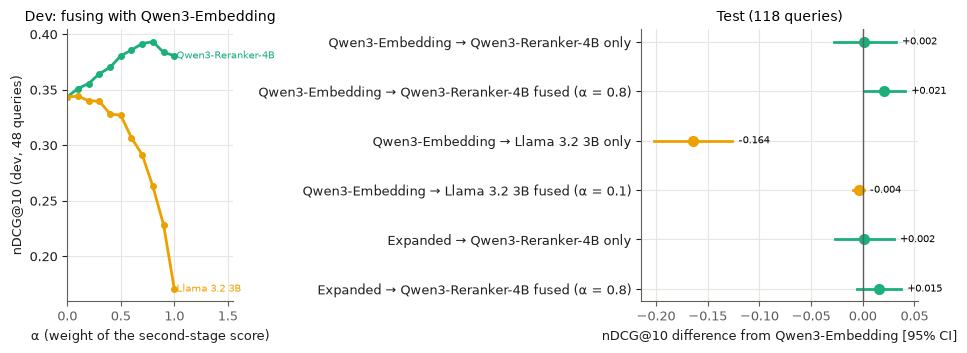

In [10]:
import matplotlib.pyplot as plt

from src.figures import FAMILY_COLOR, INK_2, SLOTS

COLOR = {"Llama 3.2 3B": FAMILY_COLOR["LLM"], "Qwen3-Reranker-4B": SLOTS[2]}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), gridspec_kw={"width_ratios": [0.9, 1.5]})
ax = axes[0]
for s in caches:
    d = dev_tab[(dev_tab.scorer == s) & (dev_tab["list"] == "Qwen3-Embedding")]
    ax.plot(d.alpha, d["ndcg@10"], "o-", color=COLOR[s], ms=4)
    ax.text(1.02, d["ndcg@10"].iloc[-1], s, color=COLOR[s], fontsize=7.5, va="center")
ax.set_xlabel("α (weight of the second-stage score)")
ax.set_ylabel("nDCG@10 (dev, 48 queries)")
ax.set_title("Dev: fusing with Qwen3-Embedding")
ax.set_xlim(0, 1.55)

ax = axes[1]
show = test_tab[test_tab.condition != "Qwen3-Embedding (first stage)"].reset_index(drop=True)
for i, r in show.iterrows():
    lo, hi = [float(v) for v in r["d_ndcg@10_ci"].strip("[]").split(", ")]
    color = COLOR["Qwen3-Reranker-4B"] if "Qwen3-Reranker" in r.condition else COLOR["Llama 3.2 3B"]
    ax.plot([lo, hi], [i, i], color=color, lw=2)
    ax.plot(r["d_ndcg@10"], i, "o", color=color)
    ax.text(max(hi, r["d_ndcg@10"]) + 0.006, i, f"{r['d_ndcg@10']:+.3f}", va="center", fontsize=7.5)
ax.axvline(0, color=INK_2, lw=1)
ax.set_yticks(range(len(show)), show.condition)
ax.invert_yaxis()
ax.set_xlabel("nDCG@10 difference from Qwen3-Embedding [95% CI]")
ax.set_title("Test (118 queries)")
fig.tight_layout()
save(fig, "12_qwen3_reranker")
plt.show()

### Findings

- **Scoring.** 17,939 pairs, all status ok, no NaNs: 256.9 min at 0.859 s per pair.
  - A 32-pair probe had measured 0.455 s. Late in the run, swap was 25.8 of 26.6 GB in use (other apps plus idle llama-server models), which roughly halved the speed.
- **Qwen3-Reranker-4B separates cited papers from the other listed candidates better than anything else here.** The within-list AUC on test is **0.824**, against 0.761 for Qwen3-Embedding and 0.663 for Llama 3.2 3B. Dev shows the same order.
- **Dev α.** Unlike Llama, mixing in the reranker helps on dev: nDCG@10 rises from 0.344 (α = 0) to 0.393 at **α = 0.8** (alone 0.381).
- **Test, Qwen3-Embedding list** (118 queries). The Holm correction runs over the 6 conditions, Llama's included.
  - **Reranker alone:** nDCG@10 0.341 (+0.002 [−0.028, +0.032]), R-precision +2.2 [−0.3, +4.7]. Neither is significant.
  - **Fused, α = 0.8:**
    - nDCG@10 0.360 (**+0.021 [+0.001, +0.041]**, p = 0.044, Holm 0.22);
    - R-precision 28.3% vs 25.1% (**+3.2 [+1.2, +5.2]**, p = 0.008, Holm 0.040);
    - MRR 0.629 vs 0.608; recall@20 45.3% vs 40.9%.
  - **Llama 3.2 3B** for comparison: −0.164 alone, −0.004 fused.
- **Test, co-citation expanded list.** Fused gives nDCG@10 +0.015 [−0.006, +0.037] (Holm 0.61) and R-precision +2.7 [+0.6, +4.7] (p = 0.021, Holm 0.083). Graph-recovered positives rarely reach the top: 0 in the fused top 10 and 3 in the top 20; the reranker alone puts 2 in the top 10 (5.9).
- **Conclusion.** A model trained for reranking does what a small general LLM could not: it improves the full-corpus first stage. The gain is modest, about 3 points of R-precision (significant after Holm) and +0.02 nDCG@10 (not significant after Holm). It needs fusion with the embedding score; used alone it only matches the first stage. Co-citation expansion adds nothing on top.
  - **Validity.** The model (2025) may have seen the query papers and their references in pretraining (see the top cell).
- **Figure.** `12_qwen3_reranker`.
